In [ ]:
import os

# ডাউনলোড হওয়া ফোল্ডারের ফাইলসমূহ দেখার জন্য
print(os.listdir('/kaggle/working/Bangladeshi-license-plate-2'))

In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="5Ui4zugEMQnZ10Y8dmNa")
project = rf.workspace("masudvision").project("bangladeshi-license-plate-oyj2h")
version = project.version(2)
dataset = version.download("yolov8")



In [ ]:
# Ultralytics library install korun
!pip install ultralytics

import os
# Apnar downloaded dataset-er path check korun (dir name change hote pare)
dataset_path = '/kaggle/working/Bangladeshi-license-plate-2'
print(os.listdir(dataset_path))

In [ ]:
# ১. Ultralytics ইনস্টল
!pip install ultralytics

import os
from ultralytics import YOLO

# ২. অটোমেটিক ডাটাসেট ফোল্ডার খুঁজে বের করা
dataset_dir = None
for item in os.listdir('/kaggle/working'):
    if os.path.isdir(os.path.join('/kaggle/working', item)) and 'license-plate' in item.lower():
        dataset_dir = os.path.join('/kaggle/working', item)
        break

# যদি নাম না মেলে তবে সরাসরি নাম ব্যবহার করবে
if not dataset_dir:
    dataset_dir = '/kaggle/working/Bangladeshi-license-plate-2'

yaml_path = os.path.join(dataset_dir, 'data.yaml')
print(f"Dataset Path Found: {yaml_path}")

# ৩. YOLOv8 মডেল লোড ও ট্রেনিং শুরু
model = YOLO('yolov8n.pt')

results = model.train(
    data=yaml_path,
    epochs=30,
    imgsz=640,
    batch=16,
    device=0
)

In [4]:
# Stable ebong Fast Training Code (OOM Error Fixed)
!pip install roboflow ultralytics

import os
from roboflow import Roboflow
from ultralytics import YOLO

# Dataset download
rf = Roboflow(api_key="5Ui4zugEMQnZ10Y8dmNa")
project = rf.workspace("masudvision").project("bangladeshi-license-plate-oyj2h")
version = project.version(2)
dataset = version.download("yolov8")

dataset_path = dataset.location
yaml_path = os.path.join(dataset_path, 'data.yaml')

# Model load
model = YOLO('yolov8n.pt')

# Training code (Memory-optimized for Dual GPU)
results = model.train(
    data=yaml_path,
    epochs=30,
    imgsz=640,
    batch=32,        # Dual GPU er jonno safe batch size 32
    workers=2,       # RAM safe rakhar jonno workers 2 kora holo
    device='0,1',    # Dual T4 GPU active rakhar jonno
    amp=True         # Mixed Precision Training (Speed bariye rakbe)
)

loading Roboflow workspace...
loading Roboflow project...
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Bangladeshi-license-plate-2/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_rati

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/30      2.67G      1.154     0.8045      1.204         33        640: 100% ━━━━━━━━━━━━ 325/325 4.2it/s 1:170.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 5.6it/s 8.4s0.2s
                   all       2968       3080      0.923      0.906      0.944      0.657

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      2.67G      1.137     0.7607      1.195         27        640: 100% ━━━━━━━━━━━━ 325/325 4.2it/s 1:170.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 5.6it/s 8.4s0.2s
                   all       2968       3080      0.919      0.913      0.943      0.653

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      2.68G      1.136     0.7388      1.203         30        6

Testing on image: /kaggle/working/Bangladeshi-license-plate-2/test/images/image113345_jpg.rf.4b16a685d09282793e54bbbcdf302e96.jpg

image 1/1 /kaggle/working/Bangladeshi-license-plate-2/test/images/image113345_jpg.rf.4b16a685d09282793e54bbbcdf302e96.jpg: 640x640 2 0s, 7.5ms
Speed: 0.9ms preprocess, 7.5ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/detect/predict-2


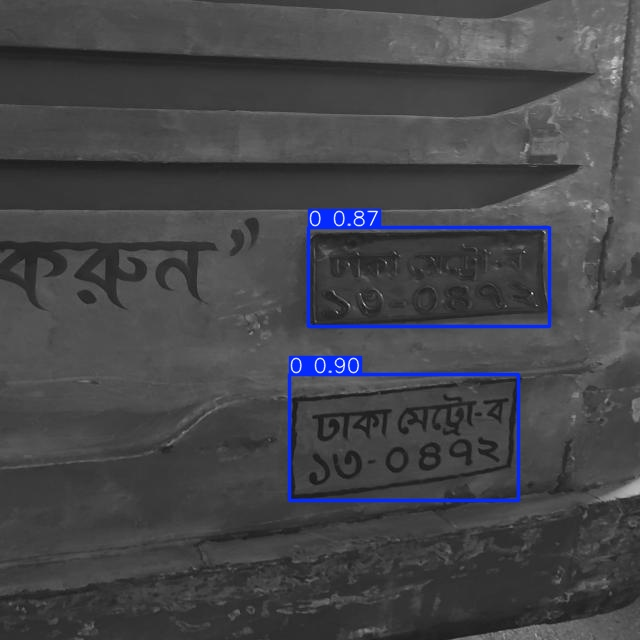

In [6]:
import os
import glob
from ultralytics import YOLO
from PIL import Image

# ১. আপনার ট্রেনিং হওয়া সেরা মডেল (best.pt) লোড করা
model = YOLO('/kaggle/working/runs/detect/train-6/weights/best.pt')

# ২. Roboflow টেস্ট ফোল্ডার থেকে একটি ছবি নেওয়া
test_images = glob.glob(f"{dataset_path}/test/images/*.jpg")

if test_images:
    sample_image = test_images[0] # প্রথম টেস্ট ছবিটি বেছে নেওয়া
    print("Testing on image:", sample_image)
    
    # ৩. প্রেডিকশন রান করা এবং আউটপুট ছবি সেভ করা
    results = model.predict(source=sample_image, save=True)
    
    # ৪. প্রেডিক্ট করা ছবি সরাসরি Kaggle-এ দেখা
    result_image_path = os.path.join(results[0].save_dir, os.path.basename(sample_image))
    display(Image.open(result_image_path))
else:
    print("Test image পাওয়া যায়নি!")

In [7]:
!pip install easyocr

Total 5 ti test image er upor prediction cholche...

--- Image 1: image113345_jpg.rf.4b16a685d09282793e54bbbcdf302e96.jpg ---

image 1/1 /kaggle/working/Bangladeshi-license-plate-2/test/images/image113345_jpg.rf.4b16a685d09282793e54bbbcdf302e96.jpg: 640x640 2 0s, 7.8ms
Speed: 1.0ms preprocess, 7.8ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/detect/predict-3


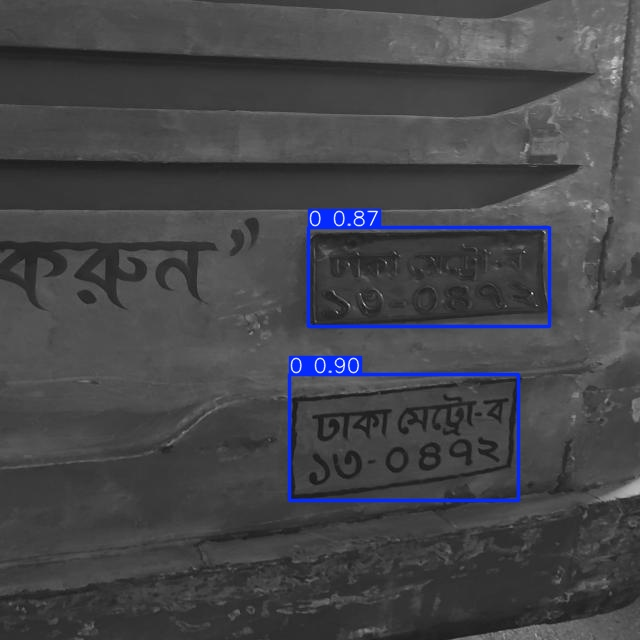

--- Image 2: image14761_jpg.rf.76ebd737d9e7ced91970e0098313605a.jpg ---

image 1/1 /kaggle/working/Bangladeshi-license-plate-2/test/images/image14761_jpg.rf.76ebd737d9e7ced91970e0098313605a.jpg: 448x640 1 0, 8.6ms
Speed: 1.6ms preprocess, 8.6ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /kaggle/working/runs/detect/predict-3


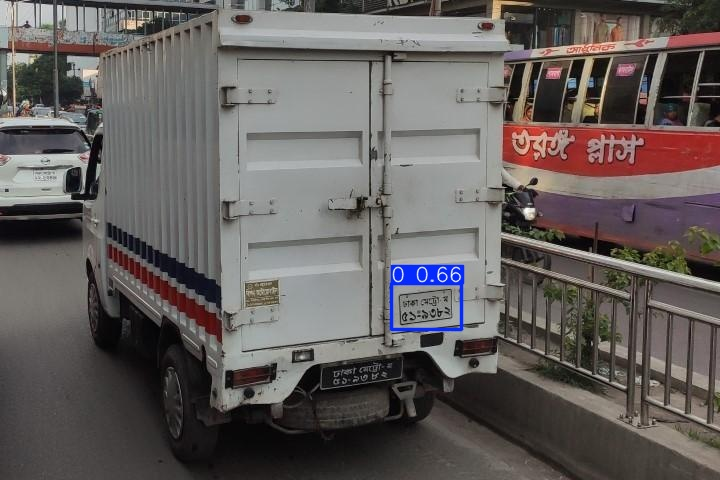

--- Image 3: image110774_jpg.rf.d936f6e5b42afa54acd68be9df76e905.jpg ---

image 1/1 /kaggle/working/Bangladeshi-license-plate-2/test/images/image110774_jpg.rf.d936f6e5b42afa54acd68be9df76e905.jpg: 640x640 1 0, 9.3ms
Speed: 0.9ms preprocess, 9.3ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/detect/predict-3


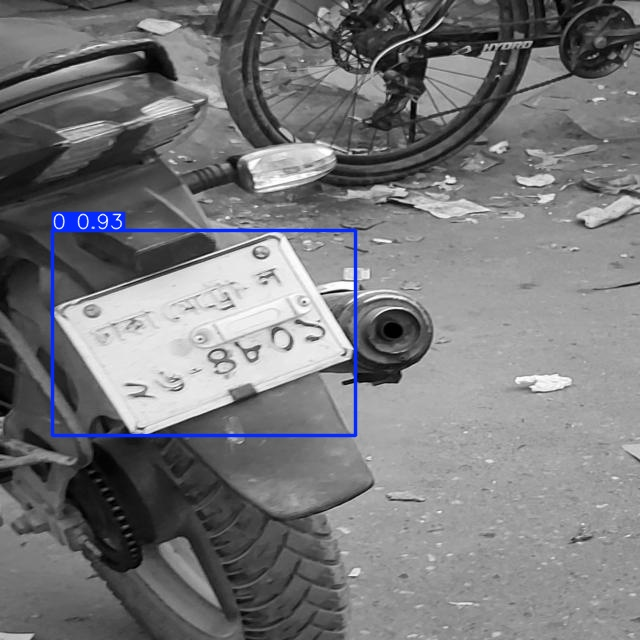

--- Image 4: image17936_jpg.rf.1e2b29acabccc9bdb94d547b1a0c5f43.jpg ---

image 1/1 /kaggle/working/Bangladeshi-license-plate-2/test/images/image17936_jpg.rf.1e2b29acabccc9bdb94d547b1a0c5f43.jpg: 640x640 1 0, 7.6ms
Speed: 0.9ms preprocess, 7.6ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/detect/predict-3


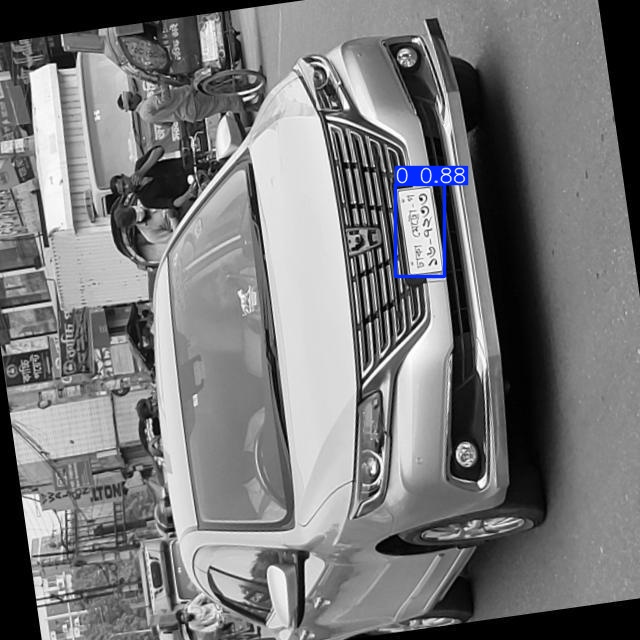

--- Image 5: image17862_jpg.rf.631eb4147bc5133e9b2c96ab46e6a981.jpg ---

image 1/1 /kaggle/working/Bangladeshi-license-plate-2/test/images/image17862_jpg.rf.631eb4147bc5133e9b2c96ab46e6a981.jpg: 480x640 1 0, 7.8ms
Speed: 1.7ms preprocess, 7.8ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /kaggle/working/runs/detect/predict-3


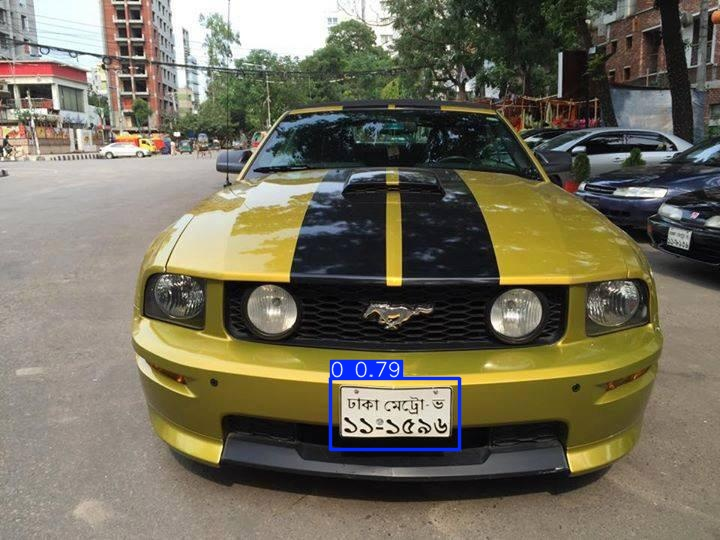

In [12]:
import os
import glob
from ultralytics import YOLO
from PIL import Image

# ১. মডেল লোড করা
model = YOLO('/kaggle/working/runs/detect/train-6/weights/best.pt')

# ২. টেস্ট ফোল্ডার থেকে ছবিগুলো নেওয়া (এখানে প্রথম ৫টি ছবি সিলেক্ট করা হয়েছে)
test_images = glob.glob(f"{dataset_path}/test/images/*.jpg")[:5]

print(f"Total {len(test_images)} ti test image er upor prediction cholche...\n")

# ৩. লুপ চালিয়ে প্রতিটি ছবির প্লেট ডিটেক্ট করা
for i, image_path in enumerate(test_images):
    print(f"--- Image {i+1}: {os.path.basename(image_path)} ---")
    
    # Predict & Save (auto saves to runs/detect/predict...)
    results = model.predict(source=image_path, conf=0.5, save=True, show=False)
    
    # রেজাল্ট ছবি Kaggle-এ শো করা
    result_image_path = os.path.join(results[0].save_dir, os.path.basename(image_path))
    if os.path.exists(result_image_path):
        display(Image.open(result_image_path))